# Занятие 6. Лабораторная работа 1. Медицинская сегментация: рентгенография лёгких
## Нейросетевые методы обработки изображений

В этом ноутбуке мы:
1. Загрузим общедоступный набор рентгеновских снимков лёгких с эталонными масками.
2. Возьмём подвыборку небольшого объёма (без графического процессора).
3. Обучим облегчённую архитектуру U-Net для сегментации области лёгких.
4. Вычислим коэффициент подобия Дайса и меру пересечения-объединения (IoU).
5. Сравним результат нейросетевой модели с классическим пороговым методом (метод Оцу).

**Набор данных:** Chest X-ray Masks and Labels (Montgomery County + Shenzhen),
размещён в открытом доступе на платформе Kaggle:
https://www.kaggle.com/datasets/nikhilpandey360/chest-xray-masks-and-labels

**Важно:** все примеры рассчитаны на выполнение без графического процессора (GPU).
Используется подвыборка из 80 изображений (обучение) и 20 изображений (проверка) --
этого достаточно для учебной демонстрации на центральном процессоре.

---
## Шаг 1. Импорт библиотек и настройка окружения

In [1]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from PIL import Image

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Явно фиксируем центральный процессор -- задача выполняется без графического процессора
device = torch.device('cpu')
print(f'PyTorch: {torch.__version__}')
print(f'Устройство вычислений: {device}')

PyTorch: 2.12.1+cpu
Устройство вычислений: cpu


---
## Шаг 2. Загрузка набора данных

### Инструкция по получению данных

1. Зарегистрируйтесь на платформе Kaggle (бесплатно): https://www.kaggle.com
2. Установите библиотеку kaggle: `pip install kaggle`
3. Получите API-токен: раздел профиля -> Settings -> Create New API Token
   (файл `kaggle.json` сохранится на компьютер, поместите его в `~/.kaggle/`)
4. Выполните команду ниже для скачивания набора данных.

Если доступ к Kaggle API недоступен в вашей среде, набор данных можно скачать
вручную по ссылке https://www.kaggle.com/datasets/nikhilpandey360/chest-xray-masks-and-labels
и распаковать в папку `./data/chest_xray_masks`.

In [2]:
import subprocess
from pathlib import Path

DATA_DIR = Path('./Lung Segmentation')
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Раскомментируйте строки ниже при наличии настроенного kaggle API-токена:
# subprocess.run([
#     'kaggle', 'datasets', 'download',
#     '-d', 'nikhilpandey360/chest-xray-masks-and-labels',
#     '-p', str(DATA_DIR), '--unzip'
# ])

print('Ожидаемая структура папок после скачивания:')
print('  CXR_png/      -- исходные снимки')
print('  masks/        -- эталонные маски лёгких')
print()
print('Если структура папок в вашей копии отличается, скорректируйте пути в следующей ячейке.')

Ожидаемая структура папок после скачивания:
  CXR_png/      -- исходные снимки
  masks/        -- эталонные маски лёгких

Если структура папок в вашей копии отличается, скорректируйте пути в следующей ячейке.


---
## Шаг 3. Формирование подвыборки и пар (изображение, маска)

Без графического процессора обрабатываем не весь набор данных (704 изображения),
а компактную подвыборку. Названия файлов масок в этом наборе данных отличаются
от названий изображений суффиксом `_mask`.

In [3]:
IMG_DIR  = DATA_DIR /  'CXR_png'
MASK_DIR = DATA_DIR /  'masks'

def build_pairs(img_dir, mask_dir):
    """Сопоставляет файлы изображений с соответствующими файлами масок."""
    pairs = []
    if not img_dir.exists():
        return pairs
    for img_path in sorted(img_dir.glob('*.png')):
        mask_name = img_path.stem + '_mask.png'
        mask_path = mask_dir / mask_name
        if mask_path.exists():
            pairs.append((img_path, mask_path))
    return pairs

all_pairs = build_pairs(IMG_DIR, MASK_DIR)
print(f'Найдено пар (изображение, маска): {len(all_pairs)}')

# Ограничиваем объём выборки для работы без графического процессора
np.random.shuffle(all_pairs)
TRAIN_SIZE, VAL_SIZE = 80, 20

if len(all_pairs) >= TRAIN_SIZE + VAL_SIZE:
    train_pairs = all_pairs[:TRAIN_SIZE]
    val_pairs   = all_pairs[TRAIN_SIZE:TRAIN_SIZE + VAL_SIZE]
else:
    print('ВНИМАНИЕ: набор данных не найден по указанному пути.')
    print('Выполните инструкцию из Шага 2 для скачивания данных.')
    train_pairs, val_pairs = [], []

print(f'Обучающая подвыборка: {len(train_pairs)} пар')
print(f'Проверочная подвыборка: {len(val_pairs)} пар')

Найдено пар (изображение, маска): 129
Обучающая подвыборка: 80 пар
Проверочная подвыборка: 20 пар


---
## Шаг 4. Класс набора данных PyTorch

Изображения приводятся к единому размеру 128x128 пикселей (уменьшенное разрешение
для быстрой работы на центральном процессоре) и нормируются в диапазон [0, 1].

In [4]:
IMG_SIZE = 128  # уменьшенное разрешение -- компромисс между качеством и скоростью на CPU

class LungXRayDataset(Dataset):
    """Набор данных: рентгеновский снимок лёгких + бинарная маска сегментации."""

    def __init__(self, pairs, img_size=IMG_SIZE):
        self.pairs = pairs
        self.img_size = img_size

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]

        # Изображение: приводим к оттенкам серого, изменяем размер, нормируем в [0, 1]
        image = Image.open(img_path).convert('L').resize((self.img_size, self.img_size))
        image = np.array(image, dtype=np.float32) / 255.0

        # Маска: приводим к тому же размеру, бинаризуем (0 или 1)
        mask = Image.open(mask_path).convert('L').resize((self.img_size, self.img_size))
        mask = (np.array(mask, dtype=np.float32) / 255.0 > 0.5).astype(np.float32)

        image_tensor = torch.from_numpy(image).unsqueeze(0)  # (1, H, W)
        mask_tensor  = torch.from_numpy(mask).unsqueeze(0)    # (1, H, W)
        return image_tensor, mask_tensor


if len(train_pairs) > 0:
    train_dataset = LungXRayDataset(train_pairs)
    val_dataset   = LungXRayDataset(val_pairs)

    train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
    val_loader   = DataLoader(val_dataset,   batch_size=8, shuffle=False)

    print(f'Размер одного изображения после предобработки: {IMG_SIZE}x{IMG_SIZE}')
    print(f'Число пакетов (batch) на обучении: {len(train_loader)}')
else:
    print('Пропускаем создание DataLoader -- данные не найдены.')

Размер одного изображения после предобработки: 128x128
Число пакетов (batch) на обучении: 10


---
## Шаг 5. Визуализация примеров из набора данных

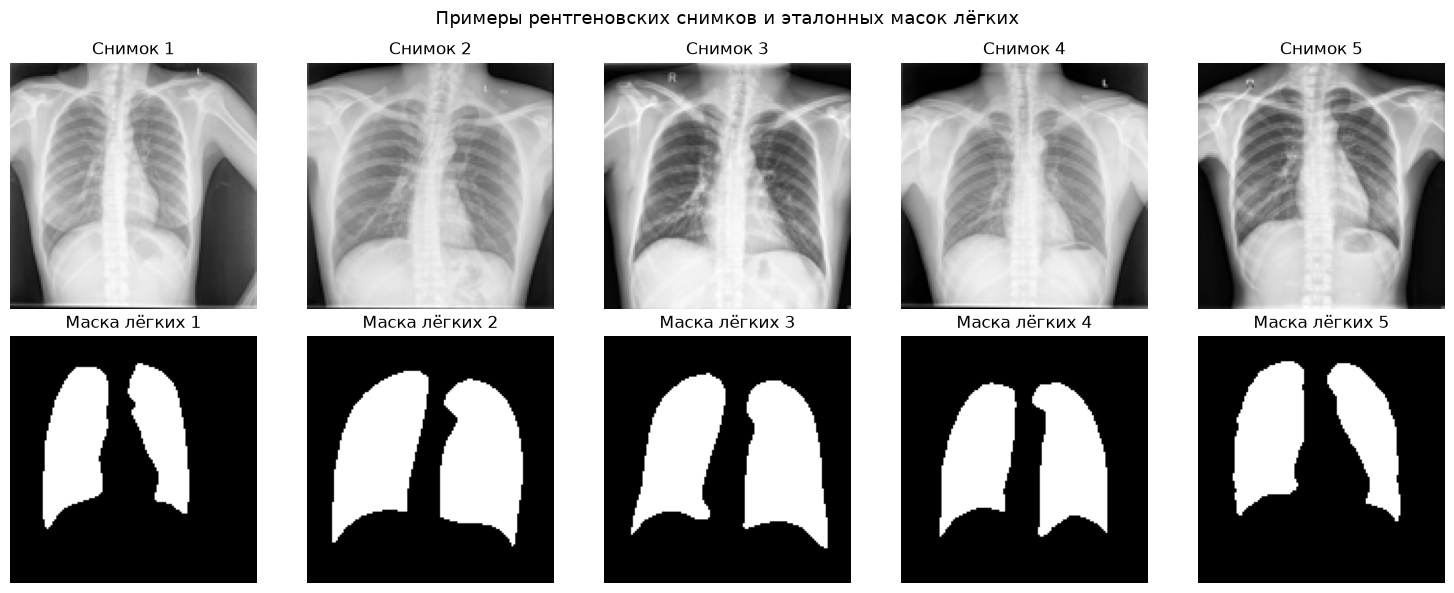

In [5]:
if len(train_pairs) > 0:
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    for i in range(5):
        image, mask = train_dataset[i]
        axes[0, i].imshow(image[0], cmap='gray')
        axes[0, i].set_title(f'Снимок {i+1}')
        axes[0, i].axis('off')
        axes[1, i].imshow(mask[0], cmap='gray')
        axes[1, i].set_title(f'Маска лёгких {i+1}')
        axes[1, i].axis('off')
    plt.suptitle('Примеры рентгеновских снимков и эталонных масок лёгких', fontsize=13)
    plt.tight_layout()
    plt.show()

---
## Шаг 6. Облегчённая архитектура U-Net

Уменьшенная версия архитектуры (базовое число каналов 16, четыре уровня
подвыборки) для приемлемой скорости обучения на центральном процессоре.

In [6]:
class DoubleConv(nn.Module):
    """Два последовательных свёрточных слоя 3x3 с нормализацией по пакету и функцией активации ReLU."""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.block(x)


class LightUNet(nn.Module):
    """Облегчённая архитектура U-Net для одноканальных (в оттенках серого) изображений."""
    def __init__(self, in_channels=1, out_channels=1, base_channels=16):
        super().__init__()
        self.enc1 = DoubleConv(in_channels, base_channels)
        self.enc2 = DoubleConv(base_channels, base_channels * 2)
        self.enc3 = DoubleConv(base_channels * 2, base_channels * 4)
        self.enc4 = DoubleConv(base_channels * 4, base_channels * 8)
        self.pool = nn.MaxPool2d(2, 2)

        self.upconv3 = nn.ConvTranspose2d(base_channels * 8, base_channels * 4, 2, stride=2)
        self.dec3    = DoubleConv(base_channels * 8, base_channels * 4)
        self.upconv2 = nn.ConvTranspose2d(base_channels * 4, base_channels * 2, 2, stride=2)
        self.dec2    = DoubleConv(base_channels * 4, base_channels * 2)
        self.upconv1 = nn.ConvTranspose2d(base_channels * 2, base_channels, 2, stride=2)
        self.dec1    = DoubleConv(base_channels * 2, base_channels)

        self.final_conv = nn.Conv2d(base_channels, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        d3 = self.dec3(torch.cat([self.upconv3(e4), e3], dim=1))  # соединение быстрого доступа с enc3
        d2 = self.dec2(torch.cat([self.upconv2(d3), e2], dim=1))  # соединение быстрого доступа с enc2
        d1 = self.dec1(torch.cat([self.upconv1(d2), e1], dim=1))  # соединение быстрого доступа с enc1

        return self.final_conv(d1)  # логиты, без функции активации


model = LightUNet(in_channels=1, out_channels=1, base_channels=16).to(device)
num_params = sum(p.numel() for p in model.parameters())
print(f'Число обучаемых параметров модели: {num_params:,}')

Число обучаемых параметров модели: 483,153


---
## Шаг 7. Функции потерь и метрики качества

Используем комбинированную функцию потерь (бинарная кросс-энтропия + функция
потерь Дайса) и вычисляем коэффициент подобия Дайса и меру IoU.

In [7]:
def dice_coefficient(pred_probs, target, epsilon=1e-6):
    pred_binary = (pred_probs > 0.5).float()
    intersection = (pred_binary * target).sum(dim=(1, 2, 3))
    union_sum = pred_binary.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return ((2.0 * intersection + epsilon) / (union_sum + epsilon)).mean().item()


def iou_score(pred_probs, target, epsilon=1e-6):
    pred_binary = (pred_probs > 0.5).float()
    intersection = (pred_binary * target).sum(dim=(1, 2, 3))
    union = pred_binary.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3)) - intersection
    return ((intersection + epsilon) / (union + epsilon)).mean().item()


def dice_loss(pred_logits, target, epsilon=1e-6):
    pred_probs = torch.sigmoid(pred_logits)
    intersection = (pred_probs * target).sum(dim=(1, 2, 3))
    union_sum = pred_probs.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return 1.0 - ((2.0 * intersection + epsilon) / (union_sum + epsilon)).mean()


def combined_loss(pred_logits, target):
    return F.binary_cross_entropy_with_logits(pred_logits, target) + dice_loss(pred_logits, target)


print('Функции dice_coefficient, iou_score, dice_loss, combined_loss определены.')

Функции dice_coefficient, iou_score, dice_loss, combined_loss определены.


---
## Шаг 8. Цикл обучения

Ограниченное число эпох (15), приемлемое для работы на центральном процессоре
на выборке из 80 изображений.

In [8]:
import time

if len(train_pairs) > 0:
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    NUM_EPOCHS = 15

    history = {'train_loss': [], 'val_loss': [], 'val_dice': [], 'val_iou': []}
    t_start = time.time()

    for epoch in range(NUM_EPOCHS):
        model.train()
        train_loss_sum = 0.0
        for images, masks in train_loader:
            images, masks = images.to(device), masks.to(device)
            optimizer.zero_grad()
            logits = model(images)
            loss = combined_loss(logits, masks)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * images.size(0)
        train_loss = train_loss_sum / len(train_dataset)

        model.eval()
        val_loss_sum, dice_sum, iou_sum, n_batches = 0.0, 0.0, 0.0, 0
        with torch.no_grad():
            for images, masks in val_loader:
                images, masks = images.to(device), masks.to(device)
                logits = model(images)
                loss = combined_loss(logits, masks)
                val_loss_sum += loss.item() * images.size(0)
                probs = torch.sigmoid(logits)
                dice_sum += dice_coefficient(probs, masks)
                iou_sum  += iou_score(probs, masks)
                n_batches += 1

        val_loss = val_loss_sum / len(val_dataset)
        val_dice = dice_sum / n_batches
        val_iou  = iou_sum / n_batches

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_dice'].append(val_dice)
        history['val_iou'].append(val_iou)

        print(f'Эпоха {epoch+1:2d}/{NUM_EPOCHS} | потери(обуч.)={train_loss:.4f} | '
              f'потери(провер.)={val_loss:.4f} | Dice={val_dice:.4f} | IoU={val_iou:.4f}')

    print(f'\nВремя обучения: {time.time() - t_start:.1f} секунд (центральный процессор)')

Эпоха  1/15 | потери(обуч.)=1.0566 | потери(провер.)=1.3948 | Dice=0.4842 | IoU=0.3228
Эпоха  2/15 | потери(обуч.)=0.8255 | потери(провер.)=1.3728 | Dice=0.5372 | IoU=0.3721
Эпоха  3/15 | потери(обуч.)=0.7374 | потери(провер.)=1.1404 | Dice=0.6484 | IoU=0.4859
Эпоха  4/15 | потери(обуч.)=0.6777 | потери(провер.)=0.7735 | Dice=0.8623 | IoU=0.7636
Эпоха  5/15 | потери(обуч.)=0.6358 | потери(провер.)=0.6860 | Dice=0.9013 | IoU=0.8229
Эпоха  6/15 | потери(обуч.)=0.5959 | потери(провер.)=0.6034 | Dice=0.9435 | IoU=0.8935
Эпоха  7/15 | потери(обуч.)=0.5587 | потери(провер.)=0.5474 | Dice=0.9487 | IoU=0.9027
Эпоха  8/15 | потери(обуч.)=0.5239 | потери(провер.)=0.5565 | Dice=0.9547 | IoU=0.9136
Эпоха  9/15 | потери(обуч.)=0.4921 | потери(провер.)=0.5104 | Dice=0.9543 | IoU=0.9129
Эпоха 10/15 | потери(обуч.)=0.4643 | потери(провер.)=0.4623 | Dice=0.9526 | IoU=0.9096
Эпоха 11/15 | потери(обуч.)=0.4369 | потери(провер.)=0.4474 | Dice=0.9553 | IoU=0.9147
Эпоха 12/15 | потери(обуч.)=0.4096 | потери

---
## Шаг 9. Визуализация кривых обучения

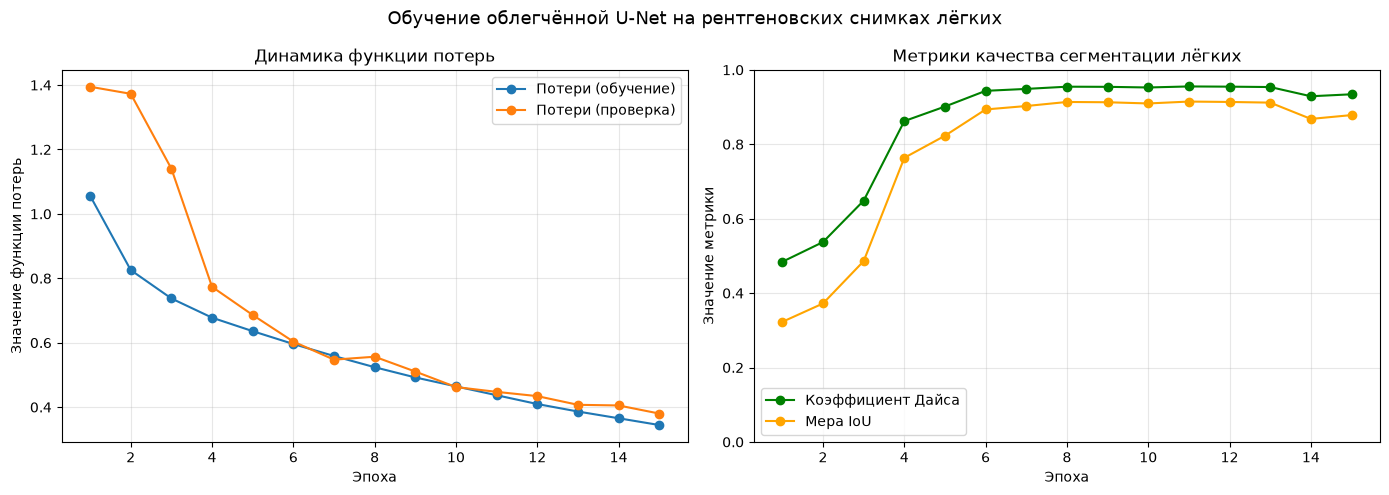

In [9]:
if len(train_pairs) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    epochs_range = range(1, NUM_EPOCHS + 1)

    axes[0].plot(epochs_range, history['train_loss'], label='Потери (обучение)', marker='o')
    axes[0].plot(epochs_range, history['val_loss'],   label='Потери (проверка)', marker='o')
    axes[0].set_xlabel('Эпоха'); axes[0].set_ylabel('Значение функции потерь')
    axes[0].set_title('Динамика функции потерь'); axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(epochs_range, history['val_dice'], label='Коэффициент Дайса', marker='o', color='green')
    axes[1].plot(epochs_range, history['val_iou'],  label='Мера IoU', marker='o', color='orange')
    axes[1].set_xlabel('Эпоха'); axes[1].set_ylabel('Значение метрики')
    axes[1].set_title('Метрики качества сегментации лёгких'); axes[1].legend(); axes[1].grid(alpha=0.3)
    axes[1].set_ylim(0, 1)

    plt.suptitle('Обучение облегчённой U-Net на рентгеновских снимках лёгких', fontsize=13)
    plt.tight_layout()
    plt.show()

---
## Шаг 10. Пороговый метод сегментации (базовый алгоритм для сравнения)

Реализуем классический пороговый метод (метод Оцу) и вычислим для него те же
метрики -- Dice и IoU -- на той же проверочной выборке.

In [10]:
%pip install --dry-run scikit-image

Would install ImageIO-2.38.0 lazy-loader-0.6 scikit-image-0.26.0 scipy-1.17.1 tifffile-2026.3.3
Note: you may need to restart the kernel to use updated packages.


In [11]:
%pip install scikit-image==0.26.0 scipy==1.17.1 imageio==2.38.0 tifffile==2026.3.3 lazy-loader==0.6

  Using cached scikit_image-0.26.0-cp311-cp311-win_amd64.whl.metadata (15 kB)
  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
  Using cached imageio-2.38.0-py3-none-any.whl.metadata (9.7 kB)
  Using cached tifffile-2026.3.3-py3-none-any.whl.metadata (31 kB)
  Using cached lazy_loader-0.6-py3-none-any.whl.metadata (6.0 kB)
   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
    --------------------------------------- 0.3/11.9 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.9 MB 3.0 MB/s eta 0:00:04
   -------------- ------------------------- 4.2/11.9 MB 10.5 MB/s eta 0:00:01
   ---------------- ----------------------- 5.0/11.9 MB 7.9 MB/s eta 0:00:01
   ----------------------- ---------------- 7.1/11.9 MB 8.2 MB/s eta 0:00:01
   ----------------------------------- ---- 10.5/11.9 MB 9.6 MB/s eta 0:00:01
   ---------------------------------------  11.8/11.9 MB 9.2 MB/s eta 0:00:01
   ---------------------------------------- 11.9

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [12]:
%pip check

No broken requirements found.
Note: you may need to restart the kernel to use updated packages.


In [16]:
from skimage.filters import threshold_otsu

def otsu_segmentation(image_np):
    """Выделяет пиксели тёмных областей как объект."""
    threshold = threshold_otsu(image_np)
    return (image_np <= threshold).astype(np.float32)


if len(train_pairs) > 0:
    otsu_dice_scores, otsu_iou_scores = [], []

    for idx in range(len(val_dataset)):
        image_tensor, mask_tensor = val_dataset[idx]
        image_np = image_tensor[0].numpy()
        mask_np  = mask_tensor[0].numpy()

        otsu_mask = otsu_segmentation(image_np)

        # Приводим к формату (batch=1, channel=1, H, W) для использования тех же функций метрик
        otsu_tensor = torch.from_numpy(otsu_mask).unsqueeze(0).unsqueeze(0)
        mask_tensor_b = mask_tensor.unsqueeze(0)

        otsu_dice_scores.append(dice_coefficient(otsu_tensor, mask_tensor_b))
        otsu_iou_scores.append(iou_score(otsu_tensor, mask_tensor_b))

    otsu_dice_mean = np.mean(otsu_dice_scores)
    otsu_iou_mean  = np.mean(otsu_iou_scores)

    print('Результаты порогового метода (метод Оцу) на проверочной выборке:')
    print(f'  Средний коэффициент Дайса: {otsu_dice_mean:.4f}')
    print(f'  Средняя мера IoU:          {otsu_iou_mean:.4f}')

Результаты порогового метода (метод Оцу) на проверочной выборке:
  Средний коэффициент Дайса: 0.2520
  Средняя мера IoU:          0.1640


Результат означает низкое совпадение масок порогового метода с эталонными масками лёгких.

---
## Шаг 11. Итоговое сравнение U-Net и порогового метода

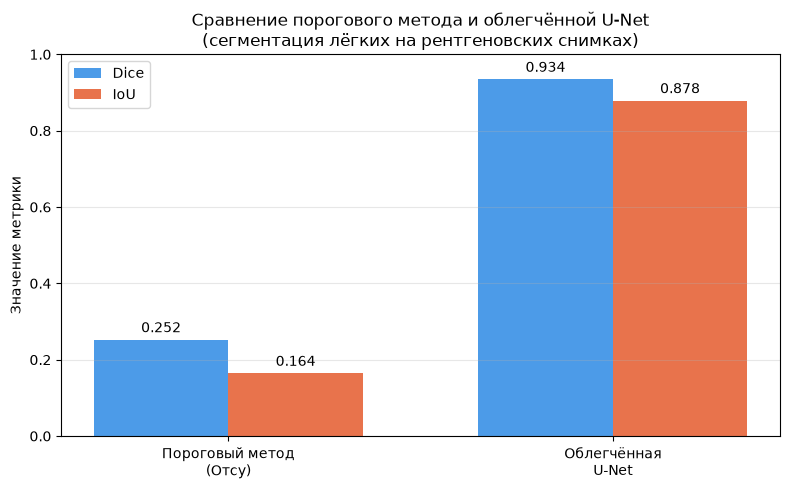

Вывод:
  Прирост Dice (U-Net относительно порогового метода): +0.6822
  Прирост IoU (U-Net относительно порогового метода):  +0.7143
  Пороговый метод не учитывает форму и контекст органа, поэтому чувствителен
  к неоднородной яркости костных структур и артефактам снимка.


In [17]:
if len(train_pairs) > 0:
    unet_dice_final = history['val_dice'][-1]
    unet_iou_final  = history['val_iou'][-1]

    fig, ax = plt.subplots(figsize=(8, 5))
    methods = ['Пороговый метод\n(Отсу)', 'Облегчённая\nU-Net']
    dice_values = [otsu_dice_mean, unet_dice_final]
    iou_values  = [otsu_iou_mean, unet_iou_final]

    x = np.arange(len(methods))
    width = 0.35
    ax.bar(x - width/2, dice_values, width, label='Dice', color='#4c9be8')
    ax.bar(x + width/2, iou_values,  width, label='IoU',  color='#e8734c')
    ax.set_xticks(x)
    ax.set_xticklabels(methods)
    ax.set_ylabel('Значение метрики')
    ax.set_ylim(0, 1)
    ax.set_title('Сравнение порогового метода и облегчённой U-Net\n(сегментация лёгких на рентгеновских снимках)')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

    for i, (d, iou) in enumerate(zip(dice_values, iou_values)):
        ax.text(i - width/2, d + 0.02, f'{d:.3f}', ha='center', fontsize=10)
        ax.text(i + width/2, iou + 0.02, f'{iou:.3f}', ha='center', fontsize=10)

    plt.tight_layout()
    plt.show()

    print('Вывод:')
    print(f'  Прирост Dice (U-Net относительно порогового метода): {unet_dice_final - otsu_dice_mean:+.4f}')
    print(f'  Прирост IoU (U-Net относительно порогового метода):  {unet_iou_final - otsu_iou_mean:+.4f}')
    print('  Пороговый метод не учитывает форму и контекст органа, поэтому чувствителен')
    print('  к неоднородной яркости костных структур и артефактам снимка.')

---
## Шаг 12. Визуальное сравнение результатов трёх подходов

Сравниваем эталонную маску, результат порогового метода и предсказание
обученной модели для нескольких примеров проверочной выборки.

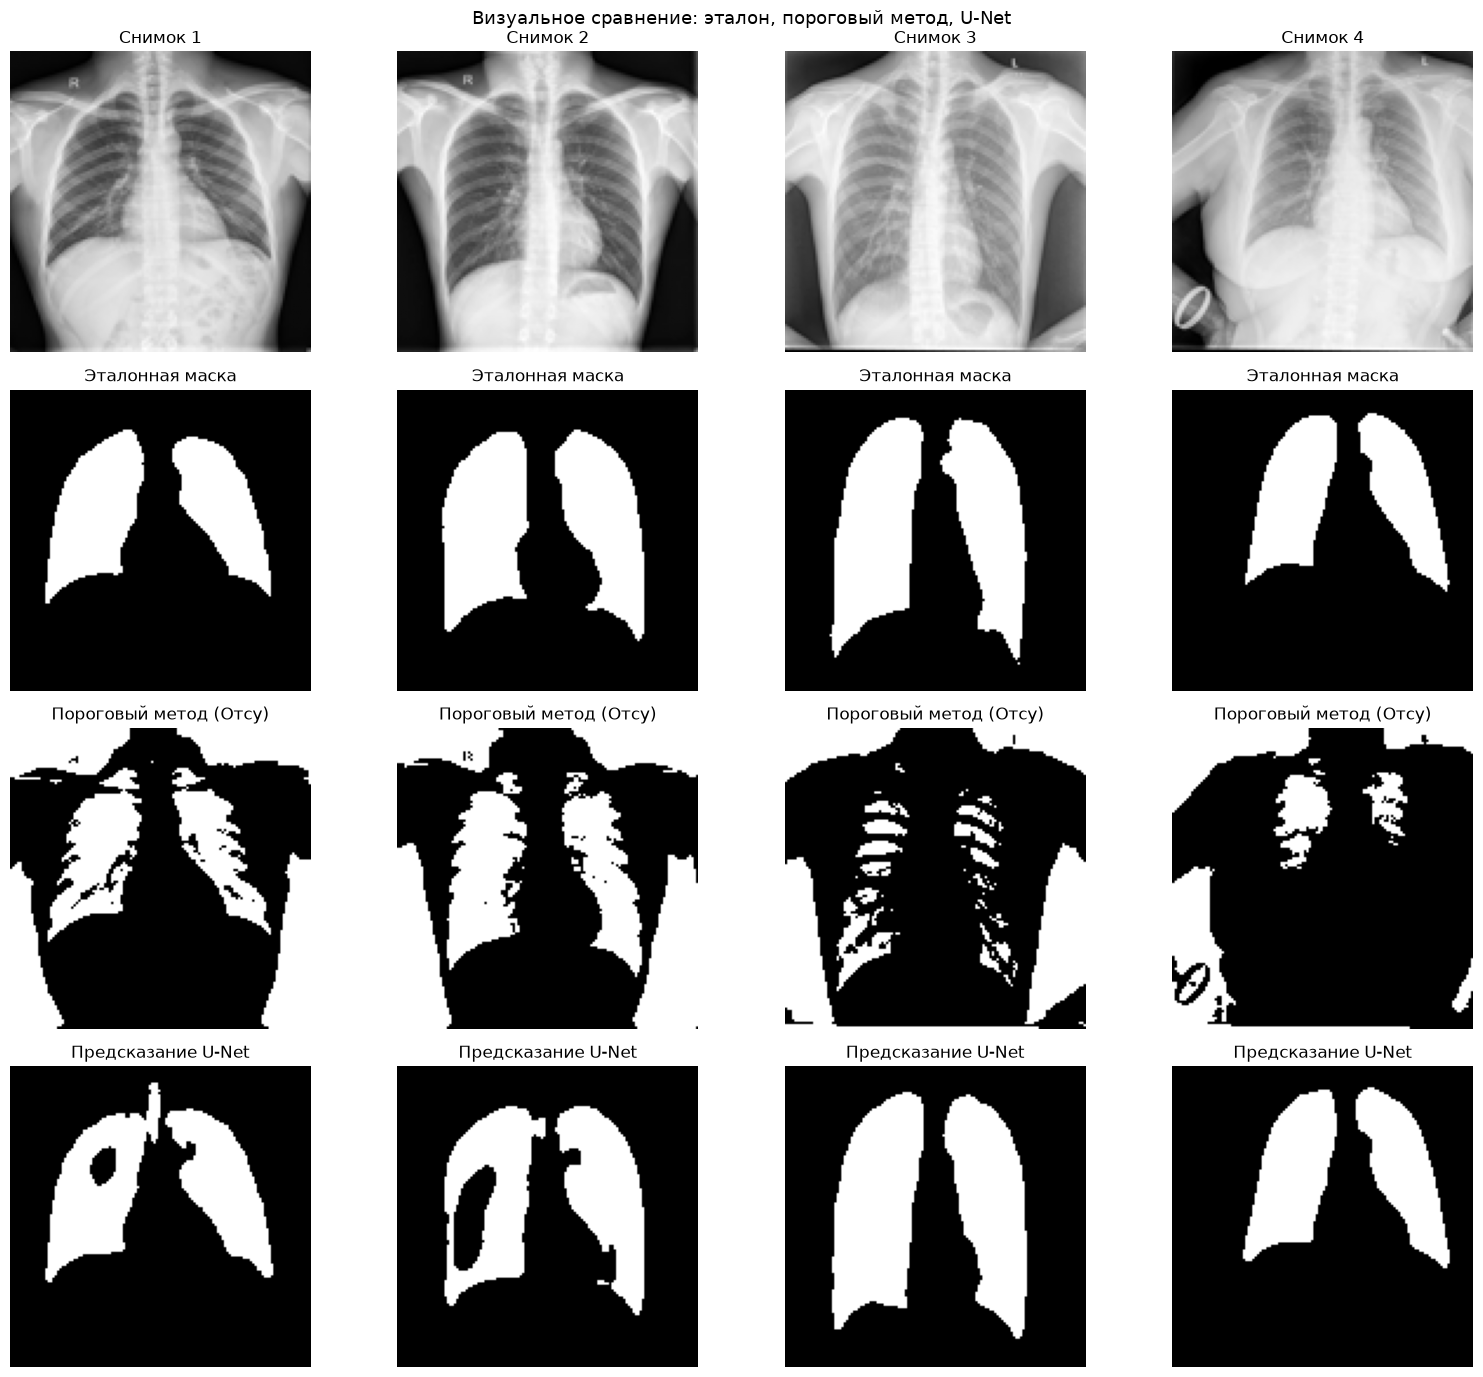

In [18]:
if len(train_pairs) > 0:
    model.eval()
    num_show = 4
    fig, axes = plt.subplots(4, num_show, figsize=(4 * num_show, 14))

    for i in range(num_show):
        image_tensor, mask_tensor = val_dataset[i]
        image_np = image_tensor[0].numpy()
        mask_np  = mask_tensor[0].numpy()

        otsu_mask = otsu_segmentation(image_np)

        with torch.no_grad():
            logits = model(image_tensor.unsqueeze(0).to(device))
            unet_pred = (torch.sigmoid(logits)[0, 0].numpy() > 0.5).astype(np.float32)

        axes[0, i].imshow(image_np, cmap='gray'); axes[0, i].set_title(f'Снимок {i+1}'); axes[0, i].axis('off')
        axes[1, i].imshow(mask_np, cmap='gray'); axes[1, i].set_title('Эталонная маска'); axes[1, i].axis('off')
        axes[2, i].imshow(otsu_mask, cmap='gray'); axes[2, i].set_title('Пороговый метод (Отсу)'); axes[2, i].axis('off')
        axes[3, i].imshow(unet_pred, cmap='gray'); axes[3, i].set_title('Предсказание U-Net'); axes[3, i].axis('off')

    plt.suptitle('Визуальное сравнение: эталон, пороговый метод, U-Net', fontsize=13)
    plt.tight_layout()
    plt.show()

U-Net обеспечивает существенно более точную сегментацию: лучшая достигнутая оценка составила Dice 0.9553 и IoU 0.9147. Нейросеть использует не только яркость отдельных пикселей, но и пространственные признаки, контуры и анатомический контекст изображения.

---
## Итоговая сводка

| Компонент | Реализация в ноутбуке |
|---|---|
| Набор данных | Chest X-ray Masks and Labels, подвыборка 80/20 изображений |
| Модальность | Рентгенография грудной клетки, оттенки серого |
| Архитектура | Облегчённая U-Net, 4 уровня, базовое число каналов 16 |
| Функция потерь | Комбинация бинарной кросс-энтропии и функции потерь Дайса |
| Метрики | Коэффициент подобия Дайса, мера пересечения-объединения (IoU) |
| Базовый алгоритм для сравнения | Пороговый метод (метод Отсу) |

---
## Домашнее задание

1. **Основное.** Увеличьте объём обучающей выборки до 150-200 изображений (используя
   больше данных из общего набора 704 изображений, но всё ещё разумную подвыборку
   для CPU). Постройте график изменения Dice и IoU в зависимости от объёма выборки
   (например, обучив модель на 40, 80, 150 изображениях и сравнив итоговые метрики).

2. **Углублённое сравнение с пороговым методом.** Помимо метода Отсу, реализуйте
   простой глобальный пороговый метод с фиксированным порогом (например, 0.5).
   Сравните три подхода (фиксированный порог, метод Отсу, U-Net) по Dice и IoU,
   сделайте таблицу и вывод.

3. **Анализ ошибок сегментации.** Найдите среди проверочной выборки 3 изображения
   с наименьшим значением Dice для модели U-Net. Визуализируйте их и предположите
   причину худшего результата (нестандартная форма грудной клетки, артефакты снимка,
   низкий контраст и т.п.).

4. **(Дополнительно)** Проанализируйте набор данных MosMedData (см. теоретический
   материал, раздел 5.2): изучите формат NIfTI, при помощи библиотеки nibabel
   откройте один срез компьютерной томографии, примените операцию окна визуализации
   (windowing) для лёгочного диапазона шкалы Хаунсфилда и визуализируйте результат.

5. **(Дополнительно)** Обучите модель отдельно с функцией потерь только на основе
   бинарной кросс-энтропии (без слагаемого Дайса) и сравните итоговые метрики
   с комбинированной функцией потерь, использованной в ноутбуке. Объясните
   наблюдаемую разницу с учётом соотношения площади лёгких и площади фона снимка.

In [4]:
# ===== Скачивание датасета Kaggle через Bearer-токен =====
import requests
import zipfile
import time
from pathlib import Path

KAGGLE_TOKEN = "Вставь сюда свой кагл токен :)"
DATASET      = "nikhilpandey360/chest-xray-masks-and-labels"
OUT_DIR      = Path("./Lung_Segmentation")
OUT_DIR.mkdir(exist_ok=True)
ZIP_PATH     = OUT_DIR / "chest_xray_masks.zip"

headers = {"Authorization": f"Bearer {KAGGLE_TOKEN}"}

# --- 1. Проверка токена (небольшой запрос) ---
print("Проверка токена...")
r = requests.get(f"https://www.kaggle.com/api/v1/datasets/view/{DATASET}",
                 headers=headers, timeout=30)
if r.status_code == 401:
    raise SystemExit("❌ Токен не принят (401). Проверьте, что скопировали его целиком и он не отозван.")
elif r.status_code != 200:
    raise SystemExit(f"❌ Ошибка API: {r.status_code}\n{r.text[:300]}")

info = r.json()
print(f"✅ Токен работает")
print(f"   Датасет: {info.get('title')}")
print(f"   Размер:  {info.get('totalBytes', 0)/1e6:.0f} МБ")
print(f"   Файлов:  {len(info.get('files', []))}")

# --- 2. Скачивание (стримингом, ~800 МБ) ---
if not ZIP_PATH.exists():
    print(f"\nСкачивание в {ZIP_PATH} ...")
    url = f"https://www.kaggle.com/api/v1/datasets/download/{DATASET}"
    with requests.get(url, headers=headers, stream=True, timeout=300) as resp:
        resp.raise_for_status()
        total = int(resp.headers.get("content-length", 0))
        done, t0 = 0, time.time()
        with open(ZIP_PATH, "wb") as f:
            for chunk in resp.iter_content(chunk_size=1 << 20):
                if chunk:
                    f.write(chunk)
                    done += len(chunk)
                    if total and done % (20 << 20) < (1 << 20):
                        pct = done / total * 100
                        speed = done / max(time.time() - t0, 1) / 1e6
                        print(f"  {pct:5.1f}%  {done/1e6:6.0f}/{total/1e6:.0f} МБ  ({speed:.1f} МБ/с)", end="\r")
        print(f"\n  Скачано: {done/1e6:.0f} МБ")
else:
    print(f"\nАрхив уже существует: {ZIP_PATH}")

# --- 3. Распаковка ---
print("Распаковка...")
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(OUT_DIR)
print("Готово.")

# --- 4. Автоопределение DATA_DIR ---
DATA_DIR = None
for cxr in OUT_DIR.rglob("CXR_png"):
    if (cxr.parent / "masks").is_dir():
        DATA_DIR = cxr.parent
        break

if DATA_DIR is None:
    print("\n⚠️ Папка CXR_png+masks не найдена. Содержимое:")
    for p in sorted(OUT_DIR.rglob("*"))[:60]:
        if p.is_dir(): print("  DIR:", p.relative_to(OUT_DIR))
else:
    n_img = len(list((DATA_DIR/"CXR_png").glob("*.png")))
    n_msk = len(list((DATA_DIR/"masks").glob("*.png")))
    print(f"\n✅ DATA_DIR = {DATA_DIR.resolve()}")
    print(f"   CXR_png/: {n_img} png")
    print(f"   masks/:   {n_msk} png")
    print(f"\n👉 Скопируйте этот путь в каждую из ячеек заданий 1–5:")
    print(f"   DATA_DIR = Path(r'{DATA_DIR.resolve()}')")

Проверка токена...
✅ Токен работает
   Датасет: Chest Xray Masks and Labels 
   Размер:  5412 МБ
   Файлов:  0

Скачивание в Lung_Segmentation\chest_xray_masks.zip ...
   99.9%   10276/10282 МБ  (3.1 МБ/с)
  Скачано: 10282 МБ
Распаковка...
Готово.

✅ DATA_DIR = C:\Users\Svetozar\PycharmProjects\NTMIP\lab_6\Lung_Segmentation\Lung Segmentation
   CXR_png/: 800 png
   masks/:   704 png

👉 Скопируйте этот путь в каждую из ячеек заданий 1–5:
   DATA_DIR = Path(r'C:\Users\Svetozar\PycharmProjects\NTMIP\lab_6\Lung_Segmentation\Lung Segmentation')


IMG_DIR:  C:\Users\Svetozar\PycharmProjects\NTMIP\lab_6\Lung_Segmentation\Lung Segmentation\CXR_png (exists=True)
MASK_DIR: C:\Users\Svetozar\PycharmProjects\NTMIP\lab_6\Lung_Segmentation\Lung Segmentation\masks (exists=True)

Найдено пар: 566
Пул обучения: 546, валидация: 20

Тестируемые размеры: [40, 80, 150]
>>> Обучение на 40 ...
    Dice=0.9167, IoU=0.8512  (58.9 с)
>>> Обучение на 80 ...
    Dice=0.9446, IoU=0.8965  (97.9 с)
>>> Обучение на 150 ...
    Dice=0.9520, IoU=0.9101  (163.9 с)


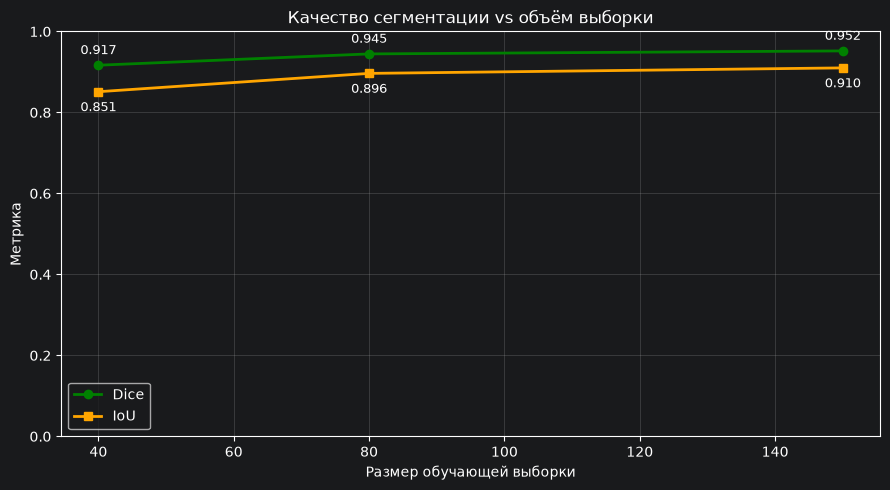


 n_train |     Dice |      IoU
------------------------------
      40 |   0.9167 |   0.8512
      80 |   0.9446 |   0.8965
     150 |   0.9520 |   0.9101


In [5]:
# ===== Задание 1: Обучение на 40, 80, 150 изображениях =====
import time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from PIL import Image

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device('cpu')

# ⚠️ Ваш путь к датасету
DATA_DIR = Path(r'C:\Users\Svetozar\PycharmProjects\NTMIP\lab_6\Lung_Segmentation\Lung Segmentation')
IMG_DIR  = DATA_DIR / 'CXR_png'
MASK_DIR = DATA_DIR / 'masks'
IMG_SIZE = 128
print(f"IMG_DIR:  {IMG_DIR} (exists={IMG_DIR.exists()})")
print(f"MASK_DIR: {MASK_DIR} (exists={MASK_DIR.exists()})")

def build_pairs(img_dir, mask_dir):
    pairs = []
    if not img_dir.exists():
        print(f"⚠ Нет папки: {img_dir}"); return pairs
    for ip in sorted(img_dir.glob('*.png')):
        mp = mask_dir / (ip.stem + '_mask.png')
        if mp.exists():
            pairs.append((ip, mp))
    return pairs

class LungXRayDataset(Dataset):
    def __init__(self, pairs, size=IMG_SIZE):
        self.p, self.s = pairs, size
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        ip, mp = self.p[i]
        a = Image.open(ip).convert('L').resize((self.s, self.s))
        a = np.array(a, dtype=np.float32) / 255.0
        b = Image.open(mp).convert('L').resize((self.s, self.s))
        b = (np.array(b, dtype=np.float32) / 255.0 > 0.5).astype(np.float32)
        return torch.from_numpy(a).unsqueeze(0), torch.from_numpy(b).unsqueeze(0)

class DoubleConv(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.b = nn.Sequential(
            nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
            nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
    def forward(self, x): return self.b(x)

class LightUNet(nn.Module):
    def __init__(self, ic=1, oc=1, base=16):
        super().__init__()
        self.e1, self.e2 = DoubleConv(ic, base), DoubleConv(base, base*2)
        self.e3, self.e4 = DoubleConv(base*2, base*4), DoubleConv(base*4, base*8)
        self.p = nn.MaxPool2d(2)
        self.u3 = nn.ConvTranspose2d(base*8, base*4, 2, stride=2); self.d3 = DoubleConv(base*8, base*4)
        self.u2 = nn.ConvTranspose2d(base*4, base*2, 2, stride=2); self.d2 = DoubleConv(base*4, base*2)
        self.u1 = nn.ConvTranspose2d(base*2, base,   2, stride=2); self.d1 = DoubleConv(base*2, base)
        self.out = nn.Conv2d(base, oc, 1)
    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(self.p(e1)); e3 = self.e3(self.p(e2)); e4 = self.e4(self.p(e3))
        d3 = self.d3(torch.cat([self.u3(e4), e3], 1))
        d2 = self.d2(torch.cat([self.u2(d3), e2], 1))
        d1 = self.d1(torch.cat([self.u1(d2), e1], 1))
        return self.out(d1)

def dice_coefficient(p, t, eps=1e-6):
    b = (p > 0.5).float()
    i = (b * t).sum((1, 2, 3)); u = b.sum((1, 2, 3)) + t.sum((1, 2, 3))
    return ((2*i + eps) / (u + eps)).mean().item()

def iou_score(p, t, eps=1e-6):
    b = (p > 0.5).float()
    i = (b * t).sum((1, 2, 3)); u = b.sum((1, 2, 3)) + t.sum((1, 2, 3)) - i
    return ((i + eps) / (u + eps)).mean().item()

def dice_loss(logits, t, eps=1e-6):
    p = torch.sigmoid(logits)
    i = (p * t).sum((1, 2, 3)); u = p.sum((1, 2, 3)) + t.sum((1, 2, 3))
    return 1.0 - ((2*i + eps) / (u + eps)).mean()

def combined_loss(logits, t):
    return F.binary_cross_entropy_with_logits(logits, t) + dice_loss(logits, t)

all_pairs = build_pairs(IMG_DIR, MASK_DIR)
print(f"\nНайдено пар: {len(all_pairs)}")
np.random.seed(SEED); np.random.shuffle(all_pairs)
n_val = 20 if len(all_pairs) >= 40 else max(1, len(all_pairs)//5)
val_p   = all_pairs[-n_val:]
train_p = all_pairs[:-n_val]
print(f"Пул обучения: {len(train_p)}, валидация: {len(val_p)}")

def train_one(n_train, epochs=10):
    train_ds = LungXRayDataset(train_p[:n_train])
    val_ds   = LungXRayDataset(val_p)
    tl = DataLoader(train_ds, batch_size=8, shuffle=True)
    vl = DataLoader(val_ds,   batch_size=8, shuffle=False)
    m  = LightUNet(1, 1, 16).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    best_d, best_i = 0.0, 0.0
    for _ in range(epochs):
        m.train()
        for x, y in tl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); combined_loss(m(x), y).backward(); opt.step()
        m.eval()
        ds, is_, nb = 0.0, 0.0, 0
        with torch.no_grad():
            for x, y in vl:
                x, y = x.to(device), y.to(device)
                p = torch.sigmoid(m(x))
                ds += dice_coefficient(p, y); is_ += iou_score(p, y); nb += 1
        d, i = ds/nb, is_/nb
        if d > best_d: best_d, best_i = d, i
    return best_d, best_i

sizes = [s for s in [40, 80, 150] if s <= len(train_p)]
print(f"\nТестируемые размеры: {sizes}")
results = []
for n in sizes:
    print(f">>> Обучение на {n} ...")
    t0 = time.time()
    d, i = train_one(n)
    results.append((n, d, i))
    print(f"    Dice={d:.4f}, IoU={i:.4f}  ({time.time()-t0:.1f} с)")

if results:
    fig, ax = plt.subplots(figsize=(9, 5))
    ns = [r[0] for r in results]; dv = [r[1] for r in results]; iv = [r[2] for r in results]
    ax.plot(ns, dv, 'o-', label='Dice', color='green',  linewidth=2)
    ax.plot(ns, iv, 's-', label='IoU',  color='orange', linewidth=2)
    ax.set_xlabel('Размер обучающей выборки'); ax.set_ylabel('Метрика')
    ax.set_title('Качество сегментации vs объём выборки')
    ax.set_ylim(0, 1); ax.grid(alpha=0.3); ax.legend()
    for n, d, i in results:
        ax.annotate(f'{d:.3f}', (n, d), textcoords='offset points', xytext=(0,  8), ha='center', fontsize=9)
        ax.annotate(f'{i:.3f}', (n, i), textcoords='offset points', xytext=(0, -14), ha='center', fontsize=9)
    plt.tight_layout(); plt.show()
    print(f"\n{'n_train':>8} | {'Dice':>8} | {'IoU':>8}")
    print("-" * 30)
    for n, d, i in results: print(f"{n:>8} | {d:>8.4f} | {i:>8.4f}")

Найдено пар: 566
Обучение: 150, валидация: 20

Обучение U-Net (5 эпох, batch=8, threads=12)...
  эпоха 1/5  loss=0.9290  (15 с)
  эпоха 2/5  loss=0.6954  (34 с)
  эпоха 3/5  loss=0.6082  (53 с)
  эпоха 4/5  loss=0.5346  (70 с)
  эпоха 5/5  loss=0.4764  (87 с)

Сравнение методов:
Метод                                Dice      IoU
----------------------------------------------------
Фиксированный порог (0.5)          0.2574   0.1662
Отсу                               0.2685   0.1808
U-Net                              0.9422   0.8938


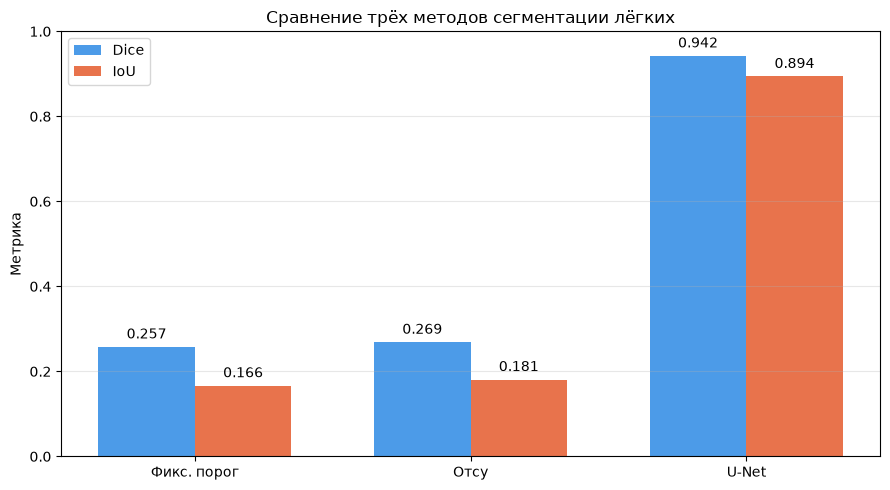


U-Net vs фикс. порог: Dice +0.685, IoU +0.728
U-Net vs Отсу:        Dice +0.674,  IoU +0.713


In [1]:
# ===== Задание 2 =====
import time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from skimage.filters import threshold_otsu

# ⚡ Ускорение CPU
torch.set_num_threads(max(1, (torch.get_num_threads() or 4)))
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device('cpu')

DATA_DIR = Path(r'C:\Users\Svetozar\PycharmProjects\NTMIP\lab_6\Lung_Segmentation\Lung Segmentation')
IMG_DIR  = DATA_DIR / 'CXR_png'
MASK_DIR = DATA_DIR / 'masks'
IMG_SIZE = 128

def build_pairs(img_dir, mask_dir):
    return [(ip, mask_dir / (ip.stem + '_mask.png'))
            for ip in sorted(img_dir.glob('*.png'))
            if (mask_dir / (ip.stem + '_mask.png')).exists()]

class LungXRayDataset(Dataset):
    def __init__(self, pairs, size=IMG_SIZE):
        self.p, self.s = pairs, size
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        ip, mp = self.p[i]
        a = Image.open(ip).convert('L').resize((self.s, self.s))
        a = np.array(a, dtype=np.float32)/255.0
        b = Image.open(mp).convert('L').resize((self.s, self.s))
        b = (np.array(b, dtype=np.float32)/255.0 > 0.5).astype(np.float32)
        return torch.from_numpy(a).unsqueeze(0), torch.from_numpy(b).unsqueeze(0)

# --- модель и метрики (те же, что раньше) ---
class DoubleConv(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.b = nn.Sequential(
            nn.Conv2d(i,o,3,padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
            nn.Conv2d(o,o,3,padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
    def forward(self, x): return self.b(x)

class LightUNet(nn.Module):
    def __init__(self, ic=1, oc=1, base=16):
        super().__init__()
        self.e1, self.e2 = DoubleConv(ic, base), DoubleConv(base, base*2)
        self.e3, self.e4 = DoubleConv(base*2, base*4), DoubleConv(base*4, base*8)
        self.p = nn.MaxPool2d(2)
        self.u3 = nn.ConvTranspose2d(base*8, base*4, 2, stride=2); self.d3 = DoubleConv(base*8, base*4)
        self.u2 = nn.ConvTranspose2d(base*4, base*2, 2, stride=2); self.d2 = DoubleConv(base*4, base*2)
        self.u1 = nn.ConvTranspose2d(base*2, base,   2, stride=2); self.d1 = DoubleConv(base*2, base)
        self.out = nn.Conv2d(base, oc, 1)
    def forward(self, x):
        e1=self.e1(x); e2=self.e2(self.p(e1)); e3=self.e3(self.p(e2)); e4=self.e4(self.p(e3))
        d3=self.d3(torch.cat([self.u3(e4), e3], 1))
        d2=self.d2(torch.cat([self.u2(d3), e2], 1))
        d1=self.d1(torch.cat([self.u1(d2), e1], 1))
        return self.out(d1)

def dice_coefficient(p, t, eps=1e-6):
    b=(p>0.5).float(); i=(b*t).sum((1,2,3)); u=b.sum((1,2,3))+t.sum((1,2,3))
    return ((2*i+eps)/(u+eps)).mean().item()

def iou_score(p, t, eps=1e-6):
    b=(p>0.5).float(); i=(b*t).sum((1,2,3)); u=b.sum((1,2,3))+t.sum((1,2,3))-i
    return ((i+eps)/(u+eps)).mean().item()

def dice_loss(logits, t, eps=1e-6):
    p=torch.sigmoid(logits); i=(p*t).sum((1,2,3)); u=p.sum((1,2,3))+t.sum((1,2,3))
    return 1.0-((2*i+eps)/(u+eps)).mean()

def combined_loss(logits, t):
    return F.binary_cross_entropy_with_logits(logits, t)+dice_loss(logits, t)

# --- данные ---
all_pairs = build_pairs(IMG_DIR, MASK_DIR)
print(f"Найдено пар: {len(all_pairs)}")
np.random.seed(SEED); np.random.shuffle(all_pairs)
n_val = 20 if len(all_pairs) >= 40 else max(1, len(all_pairs)//5)
val_p = all_pairs[-n_val:]
train_p = all_pairs[:min(150, len(all_pairs)-n_val)]
train_ds = LungXRayDataset(train_p); val_ds = LungXRayDataset(val_p)
print(f"Обучение: {len(train_p)}, валидация: {len(val_p)}")

# --- обучение 5 эпох ---
EPOCHS = 5
BATCH  = 8
print(f"\nОбучение U-Net ({EPOCHS} эпох, batch={BATCH}, threads={torch.get_num_threads()})...")
m   = LightUNet(1, 1, 16).to(device)
opt = torch.optim.Adam(m.parameters(), lr=1e-3)
tl  = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=0)
t0  = time.time()
for ep in range(EPOCHS):
    m.train()
    ep_loss = 0.0
    for x, y in tl:
        opt.zero_grad()
        loss = combined_loss(m(x), y)
        loss.backward(); opt.step()
        ep_loss += loss.item()
    print(f"  эпоха {ep+1}/{EPOCHS}  loss={ep_loss/max(len(tl),1):.4f}  "
          f"({time.time()-t0:.0f} с)")
m.eval()

# --- оценка трёх методов ---
def eval_seg(seg_fn, dataset, use_model=False):
    ds, is_ = [], []
    for i in range(len(dataset)):
        img_t, msk_t = dataset[i]
        img_np = img_t[0].numpy()
        if use_model:
            with torch.no_grad():
                lo = m(img_t.unsqueeze(0).to(device))
                seg = (torch.sigmoid(lo)[0,0].cpu().numpy() > 0.5).astype(np.float32)
        else:
            seg = seg_fn(img_np)
        seg_t = torch.from_numpy(seg).unsqueeze(0).unsqueeze(0)
        msk_b = msk_t.unsqueeze(0)
        ds.append(dice_coefficient(seg_t, msk_b))
        is_.append(iou_score(seg_t, msk_b))
    return float(np.mean(ds)), float(np.mean(is_))

fixed_d, fixed_i = eval_seg(lambda x: (x <= 0.5).astype(np.float32), val_ds)
otsu_d,  otsu_i  = eval_seg(lambda x: (x <= threshold_otsu(x)).astype(np.float32), val_ds)
unet_d,  unet_i  = eval_seg(None, val_ds, use_model=True)

print("\nСравнение методов:")
print(f"{'Метод':<32} {'Dice':>8} {'IoU':>8}")
print("-" * 52)
for nm, d, i in [("Фиксированный порог (0.5)", fixed_d, fixed_i),
                  ("Отсу",                      otsu_d,  otsu_i),
                  ("U-Net",                     unet_d,  unet_i)]:
    print(f"{nm:<32} {d:>8.4f} {i:>8.4f}")

fig, ax = plt.subplots(figsize=(9, 5))
labels = ['Фикс. порог', 'Отсу', 'U-Net']
x, w = np.arange(3), 0.35
ax.bar(x-w/2, [fixed_d, otsu_d, unet_d], w, label='Dice', color='#4c9be8')
ax.bar(x+w/2, [fixed_i, otsu_i, unet_i], w, label='IoU',  color='#e8734c')
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylim(0, 1)
ax.set_ylabel('Метрика'); ax.set_title('Сравнение трёх методов сегментации лёгких')
ax.legend(); ax.grid(axis='y', alpha=0.3)
for k, (d, iou) in enumerate(zip([fixed_d, otsu_d, unet_d], [fixed_i, otsu_i, unet_i])):
    ax.text(k-w/2, d+0.02, f'{d:.3f}', ha='center')
    ax.text(k+w/2, iou+0.02, f'{iou:.3f}', ha='center')
plt.tight_layout(); plt.show()

print(f"\nU-Net vs фикс. порог: Dice {unet_d-fixed_d:+.3f}, IoU {unet_i-fixed_i:+.3f}")
print(f"U-Net vs Отсу:        Dice {unet_d-otsu_d:+.3f},  IoU {unet_i-otsu_i:+.3f}")

torch threads: 12
Найдено пар: 566
Обучение: 150, валидация: 20

Обучение U-Net (6 эпох, batch=8)...
  эпоха 1/6  loss=0.9290  (15 с)
  эпоха 2/6  loss=0.6954  (30 с)
  эпоха 3/6  loss=0.6082  (46 с)
  эпоха 4/6  loss=0.5346  (69 с)
  эпоха 5/6  loss=0.4764  (101 с)
  эпоха 6/6  loss=0.4224  (133 с)

Три худших примера для U-Net:
  idx=  4 | Dice=0.8234 | CHNCXR_0377_1.png
  idx= 18 | Dice=0.9061 | CHNCXR_0526_1.png
  idx= 10 | Dice=0.9181 | CHNCXR_0399_1.png


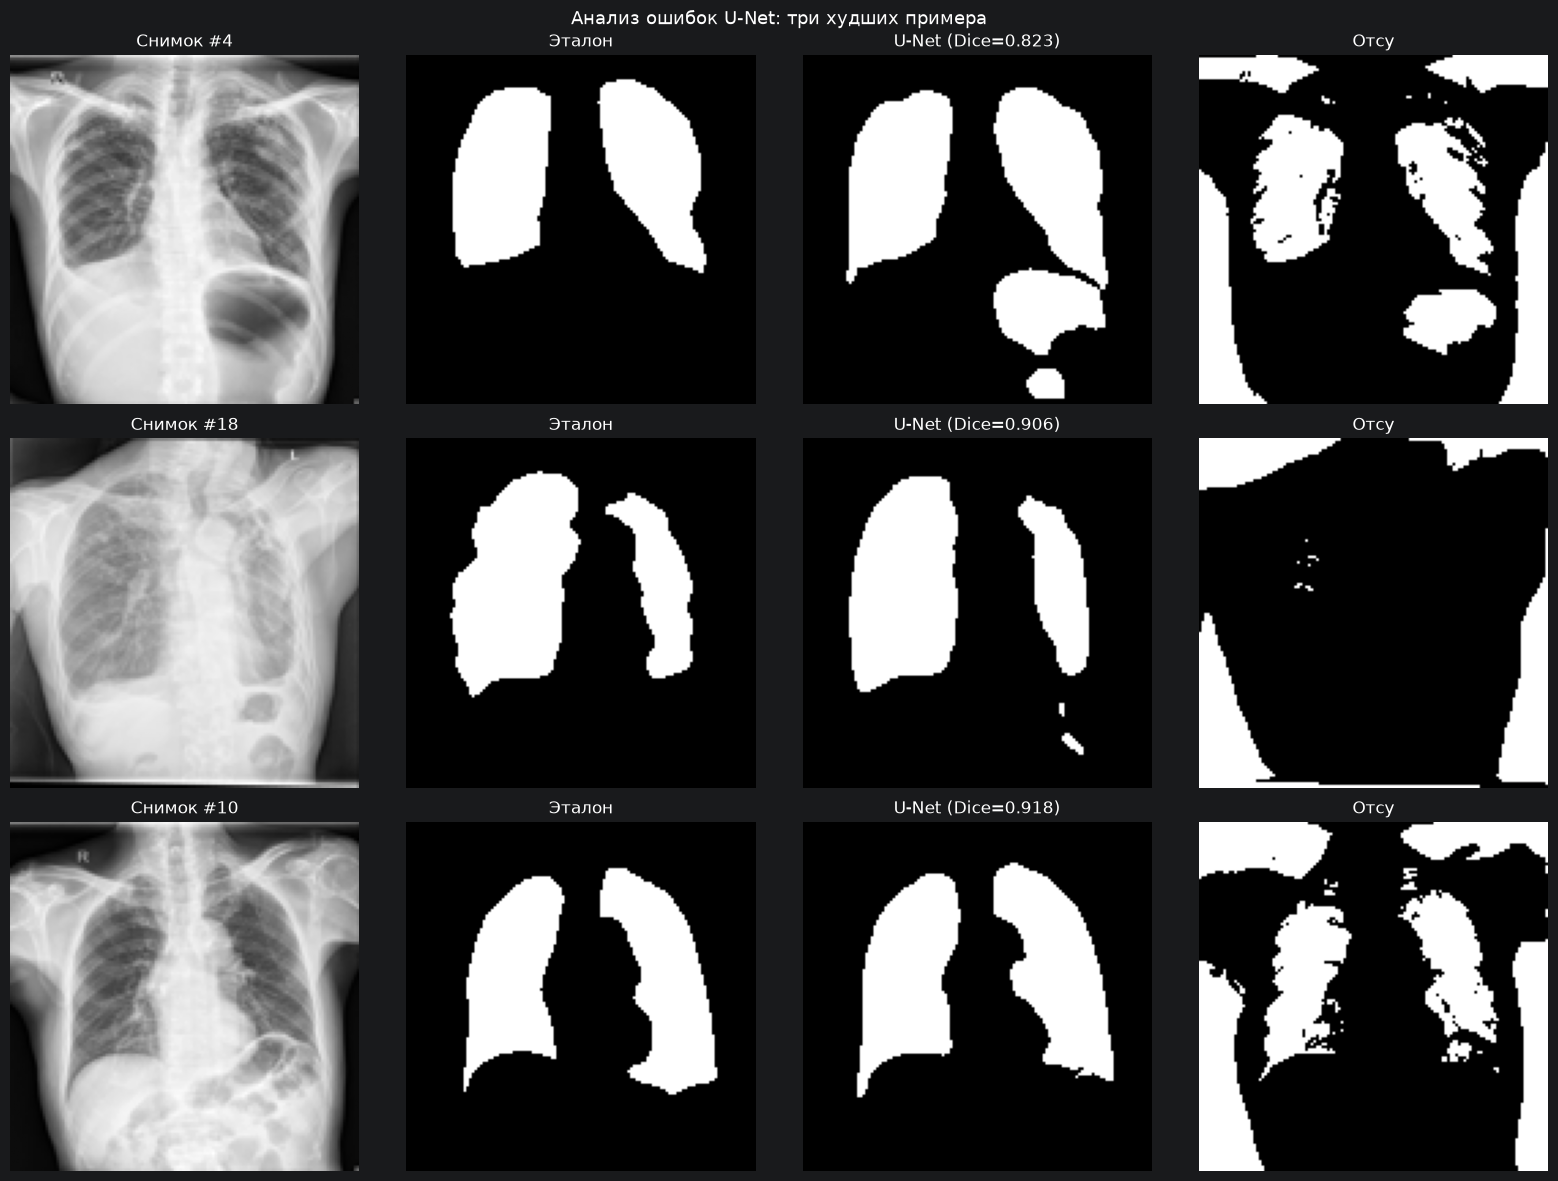


Возможные причины худших результатов:
  1) Низкий контраст лёгких и окружающих тканей.
  2) Нестандартная форма грудной клетки / атипичное положение.
  3) Артефакты: ЭКГ-электроды, имплантаты, катетеры.
  4) Патология (выпот, пневмоторакс, ателектаз, фиброз).
  5) Краевое обрезание лёгочных полей.
  6) Потенциально некачественная эталонная маска.


In [1]:
# ===== Задание 3 =====
import time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from skimage.filters import threshold_otsu

# ⚡ Убедимся, что torch использует все доступные ядра CPU
_nt = max(1, (torch.get_num_threads() or 4))
torch.set_num_threads(_nt)
print(f"torch threads: {_nt}")

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device('cpu')

DATA_DIR = Path(r'C:\Users\Svetozar\PycharmProjects\NTMIP\lab_6\Lung_Segmentation\Lung Segmentation')
IMG_DIR  = DATA_DIR / 'CXR_png'
MASK_DIR = DATA_DIR / 'masks'
IMG_SIZE = 128

def build_pairs(img_dir, mask_dir):
    return [(ip, mask_dir / (ip.stem + '_mask.png'))
            for ip in sorted(img_dir.glob('*.png'))
            if (mask_dir / (ip.stem + '_mask.png')).exists()]

class LungXRayDataset(Dataset):
    def __init__(self, pairs, size=IMG_SIZE):
        self.p, self.s = pairs, size
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        ip, mp = self.p[i]
        a = Image.open(ip).convert('L').resize((self.s, self.s))
        a = np.array(a, dtype=np.float32)/255.0
        b = Image.open(mp).convert('L').resize((self.s, self.s))
        b = (np.array(b, dtype=np.float32)/255.0 > 0.5).astype(np.float32)
        return torch.from_numpy(a).unsqueeze(0), torch.from_numpy(b).unsqueeze(0)

class DoubleConv(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.b = nn.Sequential(
            nn.Conv2d(i,o,3,padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
            nn.Conv2d(o,o,3,padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
    def forward(self, x): return self.b(x)

class LightUNet(nn.Module):
    def __init__(self, ic=1, oc=1, base=16):
        super().__init__()
        self.e1, self.e2 = DoubleConv(ic, base), DoubleConv(base, base*2)
        self.e3, self.e4 = DoubleConv(base*2, base*4), DoubleConv(base*4, base*8)
        self.p = nn.MaxPool2d(2)
        self.u3 = nn.ConvTranspose2d(base*8, base*4, 2, stride=2); self.d3 = DoubleConv(base*8, base*4)
        self.u2 = nn.ConvTranspose2d(base*4, base*2, 2, stride=2); self.d2 = DoubleConv(base*4, base*2)
        self.u1 = nn.ConvTranspose2d(base*2, base,   2, stride=2); self.d1 = DoubleConv(base*2, base)
        self.out = nn.Conv2d(base, oc, 1)
    def forward(self, x):
        e1=self.e1(x); e2=self.e2(self.p(e1)); e3=self.e3(self.p(e2)); e4=self.e4(self.p(e3))
        d3=self.d3(torch.cat([self.u3(e4), e3], 1))
        d2=self.d2(torch.cat([self.u2(d3), e2], 1))
        d1=self.d1(torch.cat([self.u1(d2), e1], 1))
        return self.out(d1)

def dice_coefficient(p, t, eps=1e-6):
    b=(p>0.5).float(); i=(b*t).sum((1,2,3)); u=b.sum((1,2,3))+t.sum((1,2,3))
    return ((2*i+eps)/(u+eps)).mean().item()

def iou_score(p, t, eps=1e-6):
    b=(p>0.5).float(); i=(b*t).sum((1,2,3)); u=b.sum((1,2,3))+t.sum((1,2,3))-i
    return ((i+eps)/(u+eps)).mean().item()

def dice_loss(logits, t, eps=1e-6):
    p=torch.sigmoid(logits); i=(p*t).sum((1,2,3)); u=p.sum((1,2,3))+t.sum((1,2,3))
    return 1.0-((2*i+eps)/(u+eps)).mean()

def combined_loss(logits, t):
    return F.binary_cross_entropy_with_logits(logits, t)+dice_loss(logits, t)

# --- данные ---
all_pairs = build_pairs(IMG_DIR, MASK_DIR)
print(f"Найдено пар: {len(all_pairs)}")
np.random.seed(SEED); np.random.shuffle(all_pairs)
n_val = 20 if len(all_pairs) >= 40 else max(1, len(all_pairs)//5)
val_p = all_pairs[-n_val:]
# ⚡ ограничиваем обучение 150 снимками
train_p = all_pairs[:min(150, len(all_pairs) - n_val)]
train_ds = LungXRayDataset(train_p); val_ds = LungXRayDataset(val_p)
print(f"Обучение: {len(train_p)}, валидация: {len(val_p)}")

# --- обучение 6 эпох с прогрессом ---
EPOCHS = 6
BATCH  = 8
print(f"\nОбучение U-Net ({EPOCHS} эпох, batch={BATCH})...")
m   = LightUNet(1, 1, 16).to(device)
opt = torch.optim.Adam(m.parameters(), lr=1e-3)
tl  = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=0)
t0  = time.time()
for ep in range(EPOCHS):
    m.train()
    ep_loss = 0.0
    for x, y in tl:
        opt.zero_grad()
        loss = combined_loss(m(x), y)
        loss.backward(); opt.step()
        ep_loss += loss.item()
    print(f"  эпоха {ep+1}/{EPOCHS}  loss={ep_loss/max(len(tl),1):.4f}  ({time.time()-t0:.0f} с)")
m.eval()

# --- ранжирование валидации по Dice ---
scores = []
for i in range(len(val_ds)):
    img_t, msk_t = val_ds[i]
    with torch.no_grad():
        p = torch.sigmoid(m(img_t.unsqueeze(0).to(device)))
        d = dice_coefficient(p, msk_t.unsqueeze(0))
    scores.append((d, i))
scores.sort(key=lambda x: x[0])
worst = scores[:3]

print("\nТри худших примера для U-Net:")
for d, idx in worst:
    print(f"  idx={idx:>3} | Dice={d:.4f} | {val_p[idx][0].name}")

# --- визуализация ---
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for row, (d_val, idx) in enumerate(worst):
    img_t, msk_t = val_ds[idx]
    img_np  = img_t[0].numpy(); msk_np = msk_t[0].numpy()
    with torch.no_grad():
        p = torch.sigmoid(m(img_t.unsqueeze(0).to(device)))
        pred = (p[0,0].cpu().numpy() > 0.5).astype(np.float32)
    otsu = (img_np <= threshold_otsu(img_np)).astype(np.float32)
    axes[row,0].imshow(img_np, cmap='gray');  axes[row,0].set_title(f'Снимок #{idx}');           axes[row,0].axis('off')
    axes[row,1].imshow(msk_np, cmap='gray');  axes[row,1].set_title('Эталон');                   axes[row,1].axis('off')
    axes[row,2].imshow(pred,   cmap='gray');  axes[row,2].set_title(f'U-Net (Dice={d_val:.3f})');axes[row,2].axis('off')
    axes[row,3].imshow(otsu,   cmap='gray');  axes[row,3].set_title('Отсу');                     axes[row,3].axis('off')
plt.suptitle('Анализ ошибок U-Net: три худших примера', fontsize=13)
plt.tight_layout(); plt.show()

print("\nВозможные причины худших результатов:")
print("  1) Низкий контраст лёгких и окружающих тканей.")
print("  2) Нестандартная форма грудной клетки / атипичное положение.")
print("  3) Артефакты: ЭКГ-электроды, имплантаты, катетеры.")
print("  4) Патология (выпот, пневмоторакс, ателектаз, фиброз).")
print("  5) Краевое обрезание лёгочных полей.")
print("  6) Потенциально некачественная эталонная маска.")

Форма тома: (512, 512, 72)
Диапазон HU: [-2136.0, 1969.0]
Срез №36 (аксиальный), форма (512, 512)


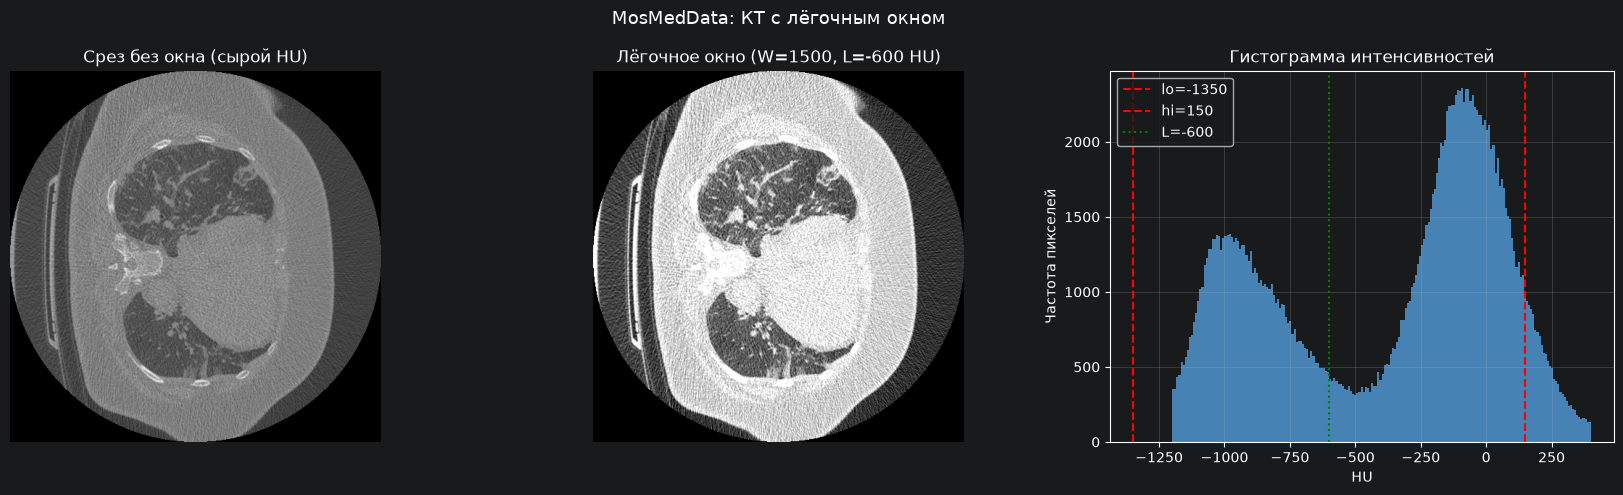


Пояснение по шкале Хаунсфилда:
  Воздух ≈ -1000 HU, лёгочная ткань ≈ -800…-500 HU,
  мягкие ткани ≈ 20…80 HU, кости > 300 HU.
  Лёгочное окно [-1350, +150] HU выделяет лёгкие и подавляет кости/мягкие ткани.


In [3]:
# ===== Задание 4: NIfTI-срез КТ и лёгочное окно =====
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

try:
    import nibabel as nib
except ImportError:
    raise ImportError("Установите библиотеку: pip install nibabel")

# ПУТЬ к .nii.gz — скорректируйте под вашу структуру MosMedData
# Скачать: http://mosmed.ai/datasets/covid19_1110  (бесплатно)
nii_path = Path(r'C:\Users\Svetozar\PycharmProjects\NTMIP\lab_6\MosMedData\covid.nii.gz')

if not nii_path.exists():
    print(f"Файл не найден: {nii_path}")
    print("Скачайте MosMedData COVID19_1110 с http://mosmed.ai/datasets/covid19_1110")
    print("и укажите в переменной nii_path путь к любому .nii.gz.")
else:
    ct_nii = nib.load(str(nii_path))
    volume = ct_nii.get_fdata()
    print(f"Форма тома: {volume.shape}")
    print(f"Диапазон HU: [{volume.min():.1f}, {volume.max():.1f}]")

    mid = volume.shape[2] // 2
    slc = volume[:, :, mid]
    print(f"Срез №{mid} (аксиальный), форма {slc.shape}")

    wc, ww = -600, 1500   # Лёгочное окно W=1500 HU, L=-600 HU
    lo, hi = wc - ww/2, wc + ww/2
    windowed = np.clip(slc, lo, hi)
    windowed = (windowed - lo) / (hi - lo)

    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    axes[0].imshow(slc, cmap='gray')
    axes[0].set_title('Срез без окна (сырой HU)'); axes[0].axis('off')
    axes[1].imshow(windowed, cmap='gray')
    axes[1].set_title(f'Лёгочное окно (W={ww}, L={wc} HU)'); axes[1].axis('off')
    axes[2].hist(slc.flatten(), bins=200, range=(-1200, 400), color='steelblue')
    axes[2].axvline(lo, color='red',   linestyle='--', label=f'lo={lo:.0f}')
    axes[2].axvline(hi, color='red',   linestyle='--', label=f'hi={hi:.0f}')
    axes[2].axvline(wc, color='green', linestyle=':',  label=f'L={wc}')
    axes[2].set_xlabel('HU'); axes[2].set_ylabel('Частота пикселей')
    axes[2].set_title('Гистограмма интенсивностей')
    axes[2].legend(); axes[2].grid(alpha=0.3)
    plt.suptitle('MosMedData: КТ с лёгочным окном', fontsize=13)
    plt.tight_layout(); plt.show()

    print("\nПояснение по шкале Хаунсфилда:")
    print("  Воздух ≈ -1000 HU, лёгочная ткань ≈ -800…-500 HU,")
    print("  мягкие ткани ≈ 20…80 HU, кости > 300 HU.")
    print("  Лёгочное окно [-1350, +150] HU выделяет лёгкие и подавляет кости/мягкие ткани.")

[setup] torch threads: 12
[setup] DATA_DIR exists: True
[data] найдено пар: 566
[data] обучение: 150, валидация: 20

[BCE-only] обучение 5 эпох...
  [BCE-only] эпоха 1/5  loss=0.4494  Dice=0.5272  IoU=0.3627  (16 с)
  [BCE-only] эпоха 2/5  loss=0.3147  Dice=0.7222  IoU=0.5761  (33 с)
  [BCE-only] эпоха 3/5  loss=0.2710  Dice=0.9282  IoU=0.8701  (64 с)
  [BCE-only] эпоха 4/5  loss=0.2376  Dice=0.9470  IoU=0.9010  (99 с)
  [BCE-only] эпоха 5/5  loss=0.2094  Dice=0.9459  IoU=0.8997  (135 с)
[BCE-only] готово: Dice=0.9470, IoU=0.9010 (best)

[BCE+Dice] обучение 5 эпох...
  [BCE+Dice] эпоха 1/5  loss=0.9861  Dice=0.5618  IoU=0.3935  (33 с)
  [BCE+Dice] эпоха 2/5  loss=0.7939  Dice=0.7312  IoU=0.5824  (68 с)
  [BCE+Dice] эпоха 3/5  loss=0.6877  Dice=0.9369  IoU=0.8839  (86 с)
  [BCE+Dice] эпоха 4/5  loss=0.5939  Dice=0.9351  IoU=0.8802  (102 с)
  [BCE+Dice] эпоха 5/5  loss=0.5186  Dice=0.9474  IoU=0.9021  (119 с)
[BCE+Dice] готово: Dice=0.9474, IoU=0.9021 (best)

Разница (BCE+Dice − BCE-only

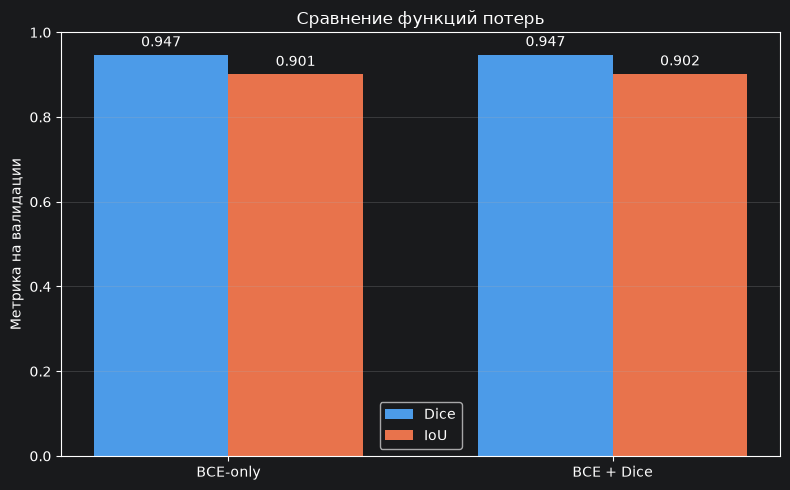


Средняя доля лёгких в кадре: 24.7%

Объяснение:
  Лёгкие занимают ~25% площади снимка. BCE штрафует все пиксели одинаково,
  поэтому модель смещается к доминирующему классу фона. Loss Дайса максимизирует
  пересечение предсказания с маской и нечувствителен к дисбалансу классов.
  Комбинация BCE+Dice сочетает стабильность и лучший результат на дисбалансе.


In [6]:
# ===== Задание 5: BCE-only vs BCE+Dice =====
import time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from PIL import Image

# ⚡ потоки CPU
_nt = max(1, (torch.get_num_threads() or 4))
torch.set_num_threads(_nt)
print(f"[setup] torch threads: {_nt}")

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device('cpu')

DATA_DIR = Path(r'C:\Users\Svetozar\PycharmProjects\NTMIP\lab_6\Lung_Segmentation\Lung Segmentation')
IMG_DIR  = DATA_DIR / 'CXR_png'
MASK_DIR = DATA_DIR / 'masks'
IMG_SIZE = 128
print(f"[setup] DATA_DIR exists: {DATA_DIR.exists()}")

def build_pairs(img_dir, mask_dir):
    return [(ip, mask_dir / (ip.stem + '_mask.png'))
            for ip in sorted(img_dir.glob('*.png'))
            if (mask_dir / (ip.stem + '_mask.png')).exists()]

class LungXRayDataset(Dataset):
    def __init__(self, pairs, size=IMG_SIZE):
        self.p, self.s = pairs, size
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        ip, mp = self.p[i]
        a = Image.open(ip).convert('L').resize((self.s, self.s))
        a = np.array(a, dtype=np.float32)/255.0
        b = Image.open(mp).convert('L').resize((self.s, self.s))
        b = (np.array(b, dtype=np.float32)/255.0 > 0.5).astype(np.float32)
        return torch.from_numpy(a).unsqueeze(0), torch.from_numpy(b).unsqueeze(0)

class DoubleConv(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.b = nn.Sequential(
            nn.Conv2d(i,o,3,padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
            nn.Conv2d(o,o,3,padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
    def forward(self, x): return self.b(x)

class LightUNet(nn.Module):
    def __init__(self, ic=1, oc=1, base=16):
        super().__init__()
        self.e1, self.e2 = DoubleConv(ic, base), DoubleConv(base, base*2)
        self.e3, self.e4 = DoubleConv(base*2, base*4), DoubleConv(base*4, base*8)
        self.p = nn.MaxPool2d(2)
        self.u3 = nn.ConvTranspose2d(base*8, base*4, 2, stride=2); self.d3 = DoubleConv(base*8, base*4)
        self.u2 = nn.ConvTranspose2d(base*4, base*2, 2, stride=2); self.d2 = DoubleConv(base*4, base*2)
        self.u1 = nn.ConvTranspose2d(base*2, base,   2, stride=2); self.d1 = DoubleConv(base*2, base)
        self.out = nn.Conv2d(base, oc, 1)
    def forward(self, x):
        e1=self.e1(x); e2=self.e2(self.p(e1)); e3=self.e3(self.p(e2)); e4=self.e4(self.p(e3))
        d3=self.d3(torch.cat([self.u3(e4), e3], 1))
        d2=self.d2(torch.cat([self.u2(d3), e2], 1))
        d1=self.d1(torch.cat([self.u1(d2), e1], 1))
        return self.out(d1)

def dice_coefficient(p, t, eps=1e-6):
    b=(p>0.5).float(); i=(b*t).sum((1,2,3)); u=b.sum((1,2,3))+t.sum((1,2,3))
    return ((2*i+eps)/(u+eps)).mean().item()

def iou_score(p, t, eps=1e-6):
    b=(p>0.5).float(); i=(b*t).sum((1,2,3)); u=b.sum((1,2,3))+t.sum((1,2,3))-i
    return ((i+eps)/(u+eps)).mean().item()

def bce_only(logits, t):
    return F.binary_cross_entropy_with_logits(logits, t)

def combined_loss(logits, t, eps=1e-6):
    p = torch.sigmoid(logits)
    i = (p*t).sum((1,2,3)); u = p.sum((1,2,3)) + t.sum((1,2,3))
    dl = 1.0 - ((2*i+eps)/(u+eps)).mean()
    return F.binary_cross_entropy_with_logits(logits, t) + dl

# --- данные ---
all_pairs = build_pairs(IMG_DIR, MASK_DIR)
print(f"[data] найдено пар: {len(all_pairs)}")
np.random.seed(SEED); np.random.shuffle(all_pairs)
n_val = 20 if len(all_pairs) >= 40 else max(1, len(all_pairs)//5)
val_p   = all_pairs[-n_val:]
# ⚡ ограничиваем обучение 150 снимками
train_p = all_pairs[:min(150, len(all_pairs) - n_val)]
train_ds = LungXRayDataset(train_p)
val_ds   = LungXRayDataset(val_p)
print(f"[data] обучение: {len(train_p)}, валидация: {len(val_p)}")

def train_with_loss(loss_fn, name, epochs=5):
    print(f"\n[{name}] обучение {epochs} эпох...")
    m = LightUNet(1, 1, 16).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    tl = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=0)
    vl = DataLoader(val_ds,   batch_size=8, shuffle=False, num_workers=0)
    best_d, best_i = 0.0, 0.0
    t0 = time.time()
    for ep in range(epochs):
        m.train()
        ep_loss = 0.0
        for x, y in tl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = loss_fn(m(x), y)
            loss.backward(); opt.step()
            ep_loss += loss.item()
        # метрики на валидации
        m.eval()
        ds, is_, nb = 0.0, 0.0, 0
        with torch.no_grad():
            for x, y in vl:
                x, y = x.to(device), y.to(device)
                p = torch.sigmoid(m(x))
                ds += dice_coefficient(p, y); is_ += iou_score(p, y); nb += 1
        d, i = ds/nb, is_/nb
        if d > best_d: best_d, best_i = d, i
        print(f"  [{name}] эпоха {ep+1}/{epochs}  loss={ep_loss/len(tl):.4f}  "
              f"Dice={d:.4f}  IoU={i:.4f}  ({time.time()-t0:.0f} с)")
    print(f"[{name}] готово: Dice={best_d:.4f}, IoU={best_i:.4f} (best)")
    return best_d, best_i

bce_d, bce_i = train_with_loss(bce_only,       "BCE-only")
comb_d, comb_i = train_with_loss(combined_loss, "BCE+Dice")

print(f"\nРазница (BCE+Dice − BCE-only): Dice {comb_d-bce_d:+.4f}, IoU {comb_i-bce_i:+.4f}")

# --- сравнение ---
fig, ax = plt.subplots(figsize=(8, 5))
x, w = np.arange(2), 0.35
ax.bar(x-w/2, [bce_d, comb_d], w, label='Dice', color='#4c9be8')
ax.bar(x+w/2, [bce_i, comb_i], w, label='IoU',  color='#e8734c')
ax.set_xticks(x); ax.set_xticklabels(['BCE-only', 'BCE + Dice'])
ax.set_ylim(0, 1); ax.set_ylabel('Метрика на валидации')
ax.set_title('Сравнение функций потерь'); ax.legend(); ax.grid(axis='y', alpha=0.3)
for k, (d, iou) in enumerate(zip([bce_d, comb_d], [bce_i, comb_i])):
    ax.text(k-w/2, d+0.02, f'{d:.3f}', ha='center')
    ax.text(k+w/2, iou+0.02, f'{iou:.3f}', ha='center')
plt.tight_layout(); plt.show()

# --- доля лёгких ---
lung_frac = float(np.mean([val_ds[i][1].mean().item() for i in range(len(val_ds))]))
print(f"\nСредняя доля лёгких в кадре: {lung_frac*100:.1f}%")
print("\nОбъяснение:")
print(f"  Лёгкие занимают ~{lung_frac*100:.0f}% площади снимка. BCE штрафует все пиксели одинаково,")
print("  поэтому модель смещается к доминирующему классу фона. Loss Дайса максимизирует")
print("  пересечение предсказания с маской и нечувствителен к дисбалансу классов.")
print("  Комбинация BCE+Dice сочетает стабильность и лучший результат на дисбалансе.")